# 07 · Results and conclusions

This notebook reads saved held-out predictions and recomputes metrics. **No training or video processing runs here.**

The lowest numerical error is not automatically the strongest evidence. Keep different datasets and evaluation protocols separate.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "training/notebooks").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from training.reporting import (
    RUNS, LABELS, result_folder, load_predictions, assert_matched_examples,
    regression_report, classification_report, metrics_table,
    plot_errors, plot_participants, plot_diagnostics, plot_warnings,
)
OUTPUT = ROOT / "training/artifacts/submission_report"
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 18)
pd.set_option("display.max_colwidth", 44)


## 1 · Experiment map

| Question | Reason to try it | Main observation |
|---|---|---|
| Original ResNet + TCN/LSTM | Establish a video baseline | Neither beat the median reference |
| Whole-lifter crops | Reduce background | Cropping alone did not solve prediction |
| R3D + adapter | Learn from motion pretraining | Small change; predictions remained weak |
| Longer history | Use more observed repetitions | Full history performed worse |
| Personal calibration | Adapt to an individual's movement | Calibration fit did not transfer reliably |
| Near-failure classification | Test a narrower target | Many false warnings |
| Speed + original shaking | Isolate the proposed extra signal | Error increased |
| Persistent/transverse shaking | Reduce tracking variation and main-motion interference | Small, fragile numerical gain |

The one-set memorization check is a training diagnostic and is excluded from test-model rankings.

## 2 · Population video models · 124 reps / six people

All rows below use the same semantic repetition targets and participant test splits. Frame hashes differ between original and cropped views. Error bars show variation between training seeds, not uncertainty over new people.

,condition,model,examples,people,seeds,mae,mae_seed_sd,rmse,within_1,within_2,bias,r2,r2_people
0,History comparison,Adapted R3D · last 4 reps,124,6,3,4.811,0.102,5.828,0.175,0.322,-0.870,-0.977,6
1,History comparison,Adapted R3D · all previous reps,124,6,3,5.232,0.136,6.072,0.155,0.288,-1.729,-1.382,6
2,History comparison,Training median,124,6,3,4.845,0.000,5.883,0.209,0.348,-0.532,-1.086,6
3,Original framing,ResNet + LSTM,124,6,3,4.941,0.126,5.989,0.137,0.267,-1.561,-1.152,6
4,Original framing,ResNet + TCN,124,6,3,5.590,0.678,6.507,0.103,0.227,0.219,-2.615,6
5,Original framing,Training median,124,6,3,4.845,0.000,5.883,0.209,0.348,-0.532,-1.086,6
6,R3D adaptation,Adapted R3D · last 4 reps,124,6,3,4.811,0.102,5.828,0.175,0.322,-0.870,-0.977,6
7,R3D adaptation,Frozen R3D + TCN,124,6,3,4.889,0.117,5.933,0.184,0.324,-0.893,-1.050,6
8,R3D adaptation,Training median,124,6,3,4.845,0.000,5.883,0.209,0.348,-0.532,-1.086,6
9,Whole-lifter crop,ResNet + LSTM,124,6,3,4.909,0.207,5.942,0.111,0.263,-1.052,-1.088,6


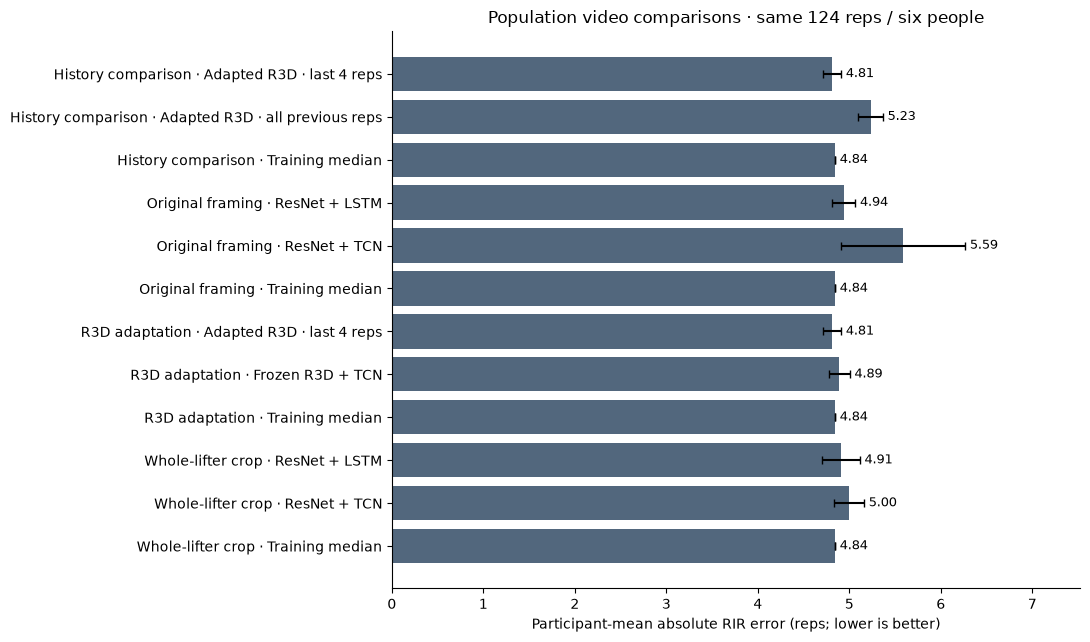

In [2]:
population_predictions = pd.concat([
    load_predictions(ROOT, "original", "Original framing"),
    load_predictions(ROOT, "cropped", "Whole-lifter crop"),
    load_predictions(ROOT, "adaptation", "R3D adaptation"),
    load_predictions(ROOT, "history", "History comparison"),
], ignore_index=True)
assert_matched_examples(population_predictions)
population_scores, population_people = regression_report(population_predictions)
display(metrics_table(population_scores))
plot_errors(population_scores, "Population video comparisons · same 124 reps / six people", OUTPUT / "07_population_models.png")
plt.show()
population_scores.to_csv(OUTPUT / "07_population_metrics.csv", index=False)
population_people.to_csv(OUTPUT / "07_population_participants.csv", index=False)


**Finding:** the rolling-four R3D adapter is the lowest-error population video model among these trials (MAE ≈ 4.81), close to the median reference (≈ 4.84). This does not establish accurate RIR prediction.

## 3 · Personal transfer · separate protocol

One calibration set and a different test set from the same person. Do not compare these numbers directly with the population MAE above.

In [3]:
personal = load_predictions(ROOT, "personalization", "Calibration S01 → S02", direction="S01_to_S02")
assert_matched_examples(personal)
personal_summary, _ = regression_report(personal)
display(metrics_table(personal_summary))
personal_summary.to_csv(OUTPUT / "07_personalization_metrics.csv", index=False)


,condition,model,examples,people,seeds,mae,mae_seed_sd,rmse,within_1,within_2,bias,r2,r2_people
0,Calibration S01 → S02,Calibration median,41,3,3,3.842,0.000,4.621,0.217,0.375,-2.167,-0.331,3
1,Calibration S01 → S02,General video model,41,3,3,3.868,0.099,4.601,0.196,0.329,-0.301,-0.512,3
2,Calibration S01 → S02,Personal offset,41,3,3,3.871,0.007,4.635,0.196,0.341,-2.178,-0.339,3
3,Calibration S01 → S02,Personal ridge head,41,3,3,4.357,0.475,5.054,0.136,0.280,-1.448,-0.743,3
4,Calibration S01 → S02,Previous set capacity,41,3,3,5.033,0.000,5.652,0.158,0.237,-5.033,-0.954,3


## 4 · Near-failure classification · 97 reps / six people

Positive means RIR 0–2, with a fixed 0.5 probability threshold. These scores answer a different question from RIR regression.

,condition,model,examples,people,seeds,balanced_accuracy,precision,recall,specificity,f1,average_precision,roc_auc,brier
0,Near failure ≤ 2 RIR,Always farther from failure,97,6,1,0.500,0.000,0.000,1.000,0.000,0.372,0.500,0.372
1,Near failure ≤ 2 RIR,Always near failure,97,6,1,0.500,0.372,1.000,0.000,0.513,0.372,0.500,0.628
2,Near failure ≤ 2 RIR,Rep durations,97,6,1,0.525,0.350,0.583,0.467,0.360,0.688,0.724,0.240
3,Near failure ≤ 2 RIR,Existing RIR ≤ 2 rule,97,6,1,0.500,0.000,0.000,1.000,0.000,0.372,0.500,0.372
4,Near failure ≤ 2 RIR,Adapted R3D classifier,97,6,3,0.502,0.328,0.889,0.116,0.451,0.444,0.519,0.260
5,Near failure ≤ 2 RIR,Video + rep durations,97,6,1,0.560,0.411,0.889,0.231,0.529,0.574,0.673,0.347
6,Near failure ≤ 2 RIR,Video features,97,6,1,0.525,0.395,0.778,0.273,0.471,0.573,0.670,0.350


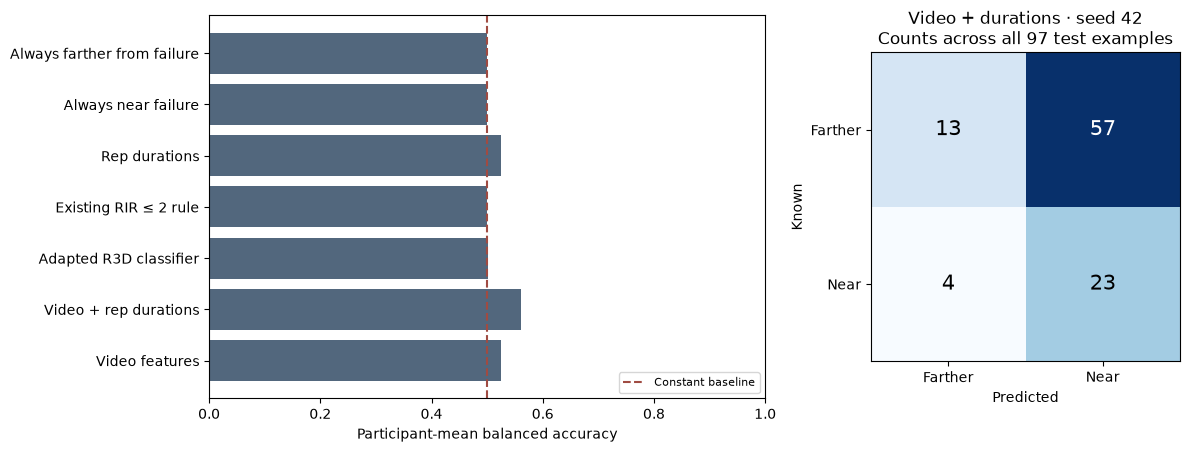

In [4]:
warnings = load_predictions(ROOT, "classification", "Near failure ≤ 2 RIR")
assert_matched_examples(warnings)
warning_summary, warning_people = classification_report(warnings)
display(metrics_table(warning_summary, classification=True))
plot_warnings(warning_summary, warnings, path=OUTPUT / "07_near_failure.png")
plt.show()
warning_summary.to_csv(OUTPUT / "07_classification_metrics.csv", index=False)


**Finding:** the best simple classifier's balanced accuracy was about 56%; high recall came with many false alarms. Ordinary accuracy or F1 alone would hide that trade-off.

## 5 · Speed and shaking · selected 33 reps / four people

These are quality-filtered optical-flow examples, not the full video-model cohort. All methods within this table use the same 33 examples. One person has just one example. The revised method was explored after seeing earlier test results.

,condition,model,examples,people,seeds,mae,mae_seed_sd,rmse,within_1,within_2,bias,r2,r2_people
0,Selected shaking cohort,Speed only,33,4,1,2.251,0.0,2.651,0.402,0.553,-0.385,-0.297,3
1,Selected shaking cohort,Speed + original shaking,33,4,1,2.882,0.0,3.361,0.152,0.288,-0.534,-0.794,3
2,Selected shaking cohort,Speed + persistent 2D shaking,33,4,1,2.734,0.0,3.235,0.400,0.531,0.157,-1.024,3
3,Selected shaking cohort,Speed + transverse shaking,33,4,1,2.221,0.0,2.645,0.402,0.553,-0.261,-0.417,3
4,Selected shaking cohort,Training median,33,4,1,2.453,0.0,2.923,0.458,0.574,0.042,-0.675,3


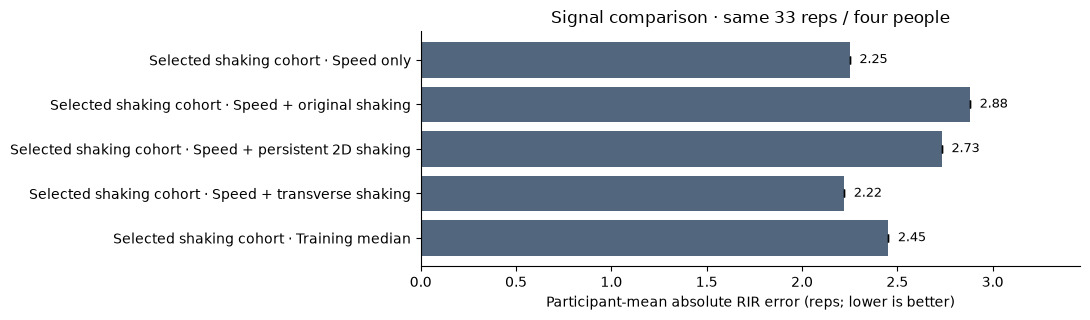

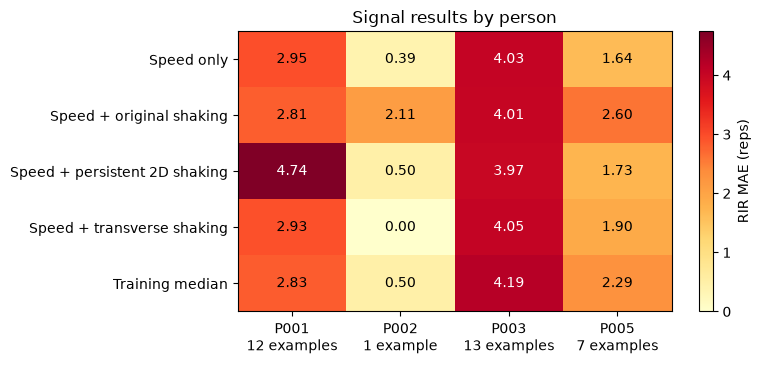

,condition,model,examples,people,seeds,mae,mae_seed_sd,rmse,within_1,within_2,bias,r2,r2_people
0,Sensitivity · three people / 32 reps,Speed only,32,3,1,2.871,0.0,3.404,0.202,0.404,-0.644,-0.297,3
1,Sensitivity · three people / 32 reps,Speed + original shaking,32,3,1,3.140,0.0,3.779,0.202,0.384,-1.414,-0.794,3
2,Sensitivity · three people / 32 reps,Speed + persistent 2D shaking,32,3,1,3.480,0.0,4.148,0.200,0.374,0.044,-1.024,3
3,Sensitivity · three people / 32 reps,Speed + transverse shaking,32,3,1,2.962,0.0,3.527,0.202,0.404,-0.348,-0.417,3
4,Sensitivity · three people / 32 reps,Training median,32,3,1,3.104,0.0,3.731,0.277,0.432,-0.111,-0.675,3


Observed matched MAE reduction: 1.32%; proposed target: 15%.


In [5]:
signals = load_predictions(ROOT, "persistent", "Selected shaking cohort")
assert_matched_examples(signals)
signal_summary, signal_people = regression_report(signals)
display(metrics_table(signal_summary))
plot_errors(signal_summary, "Signal comparison · same 33 reps / four people", OUTPUT / "07_signal_models.png")
plt.show()
plot_participants(signal_people, "Signal results by person", OUTPUT / "07_signal_people.png")
plt.show()
signal_summary.to_csv(OUTPUT / "07_signal_metrics.csv", index=False)
single = signal_people.groupby("participant_id").examples.first().loc[lambda x:x<2].index
sensitivity = signals.loc[~signals.participant_id.isin(single)].copy()
sensitivity["condition"] = "Sensitivity · three people / 32 reps"
sensitivity_summary, _ = regression_report(sensitivity)
display(metrics_table(sensitivity_summary))
sensitivity_summary.to_csv(OUTPUT / "07_signal_sensitivity.csv", index=False)
mae = signal_summary.set_index("model").mae
gain = 100 * (1 - mae["speed_plus_persistent_transverse"] / mae["speed_only"])
print(f"Observed matched MAE reduction: {gain:.2f}%; proposed target: 15%.")


**Finding:** 2.22 reps is the lowest reported test MAE in this selected subset. The 1.32% reduction versus speed alone is small, below 15%, and reverses when the single-example person is excluded. It is not convincing evidence of a tremor benefit.

## 6 · Metric guide

Metrics average each participant equally, then average training seeds. **MAE** is mean absolute error in reps; **RMSE** gives more weight to large errors. **Within 1/2** is the fraction within one/two reps. **Bias** is predicted minus known RIR: positive means too many reps predicted. R² compares with variation in known RIR; it can be negative and is undefined for a person with only one example. Seed standard deviation is not a confidence interval; one seed gives no estimate of training variability.

For classification, use precision, recall, specificity and balanced accuracy together. F1 summarizes precision/recall but ignores true negatives. ROC AUC and average precision measure ranking; Brier and log loss measure probability error. The saved CSVs include ordinary accuracy as a secondary metric. Do not use classification accuracy or F1 as exact-RIR regression scores.

## 7 · Submission conclusion

- A working video-analysis prototype and reproducible experiments were built.
- Population video RIR prediction remains weak; a training-median reference is competitive.
- Revised shaking produced a small exploratory change, not the proposed 15% benefit.
- Shaking is not sensor-validated physiological tremor, and injury reduction was not evaluated.
- Few people, uneven usable examples, approximate boundaries, uncertain public-source reuse permissions and repeated exploratory test inspection limit the conclusions.
- Models should be presented as research prototypes, not dependable advice about whether someone can safely perform another repetition.

Tables and figures are saved in `training/artifacts/submission_report/`. Source predictions and checkpoints remain unchanged.

In [6]:
print("Saved report:", OUTPUT)
display(pd.DataFrame([{"experiment": name, "source_run": folder} for name, folder in RUNS.items()]))


Saved report: /Users/zkaynl7/Projects/alu/velocity-tremor-ml/training/artifacts/submission_report


,experiment,source_run
0,original,pilot_20261030T154433983651Z
1,cropped,pilot_20261030T173732179337Z
2,learning_check,learning_check_20261030T175736034664Z
3,adaptation,r3d_adaptation_20261030T180126927110Z
4,history,r3d_history_20261030T183202356628Z
5,personalization,personalization_20261101T094914054252Z
6,classification,near_failure_20261101T100858193667Z
7,shaking,candidate_tremor_20261101T103627645167Z
8,persistent,persistent_tremor_20261101T105947439502Z


## Follow-up · Flat predictions and relative speed

A deployment check exposed poor final-rep predictions, including on a training video. Notebook 08 tests a wider Ridge regularization range, recent relative speed, and a limited nonlinear SVR comparison on the same 33 examples/four people. None improved overall participant-held-out MAE. The first-three-rep reference passed tracking checks for only two people.

The original model's final-rep MAE is about **4.59 reps**, despite its overall MAE of **2.22**. This is not a reliable failure detector. No replacement model was deployed.

,model,mae,near_failure_mae,final_rep_mae,examples,people
0,nonlinear_relative_speed,2.356,3.021,4.648,33,4
1,nonlinear_speed,2.404,3.081,4.599,33,4
2,nonlinear_speed_shaking,2.358,3.127,4.591,33,4
3,relative_speed,2.426,3.438,4.933,33,4
4,relative_speed_shaking,2.411,3.507,5.070,33,4
5,shaking_original_search,2.221,3.183,4.589,33,4
6,shaking_wider_search,2.390,3.399,4.953,33,4
7,speed_original_search,2.251,2.801,3.982,33,4
8,speed_wider_search,2.401,3.319,4.799,33,4
9,training_median,2.453,3.400,5.000,33,4


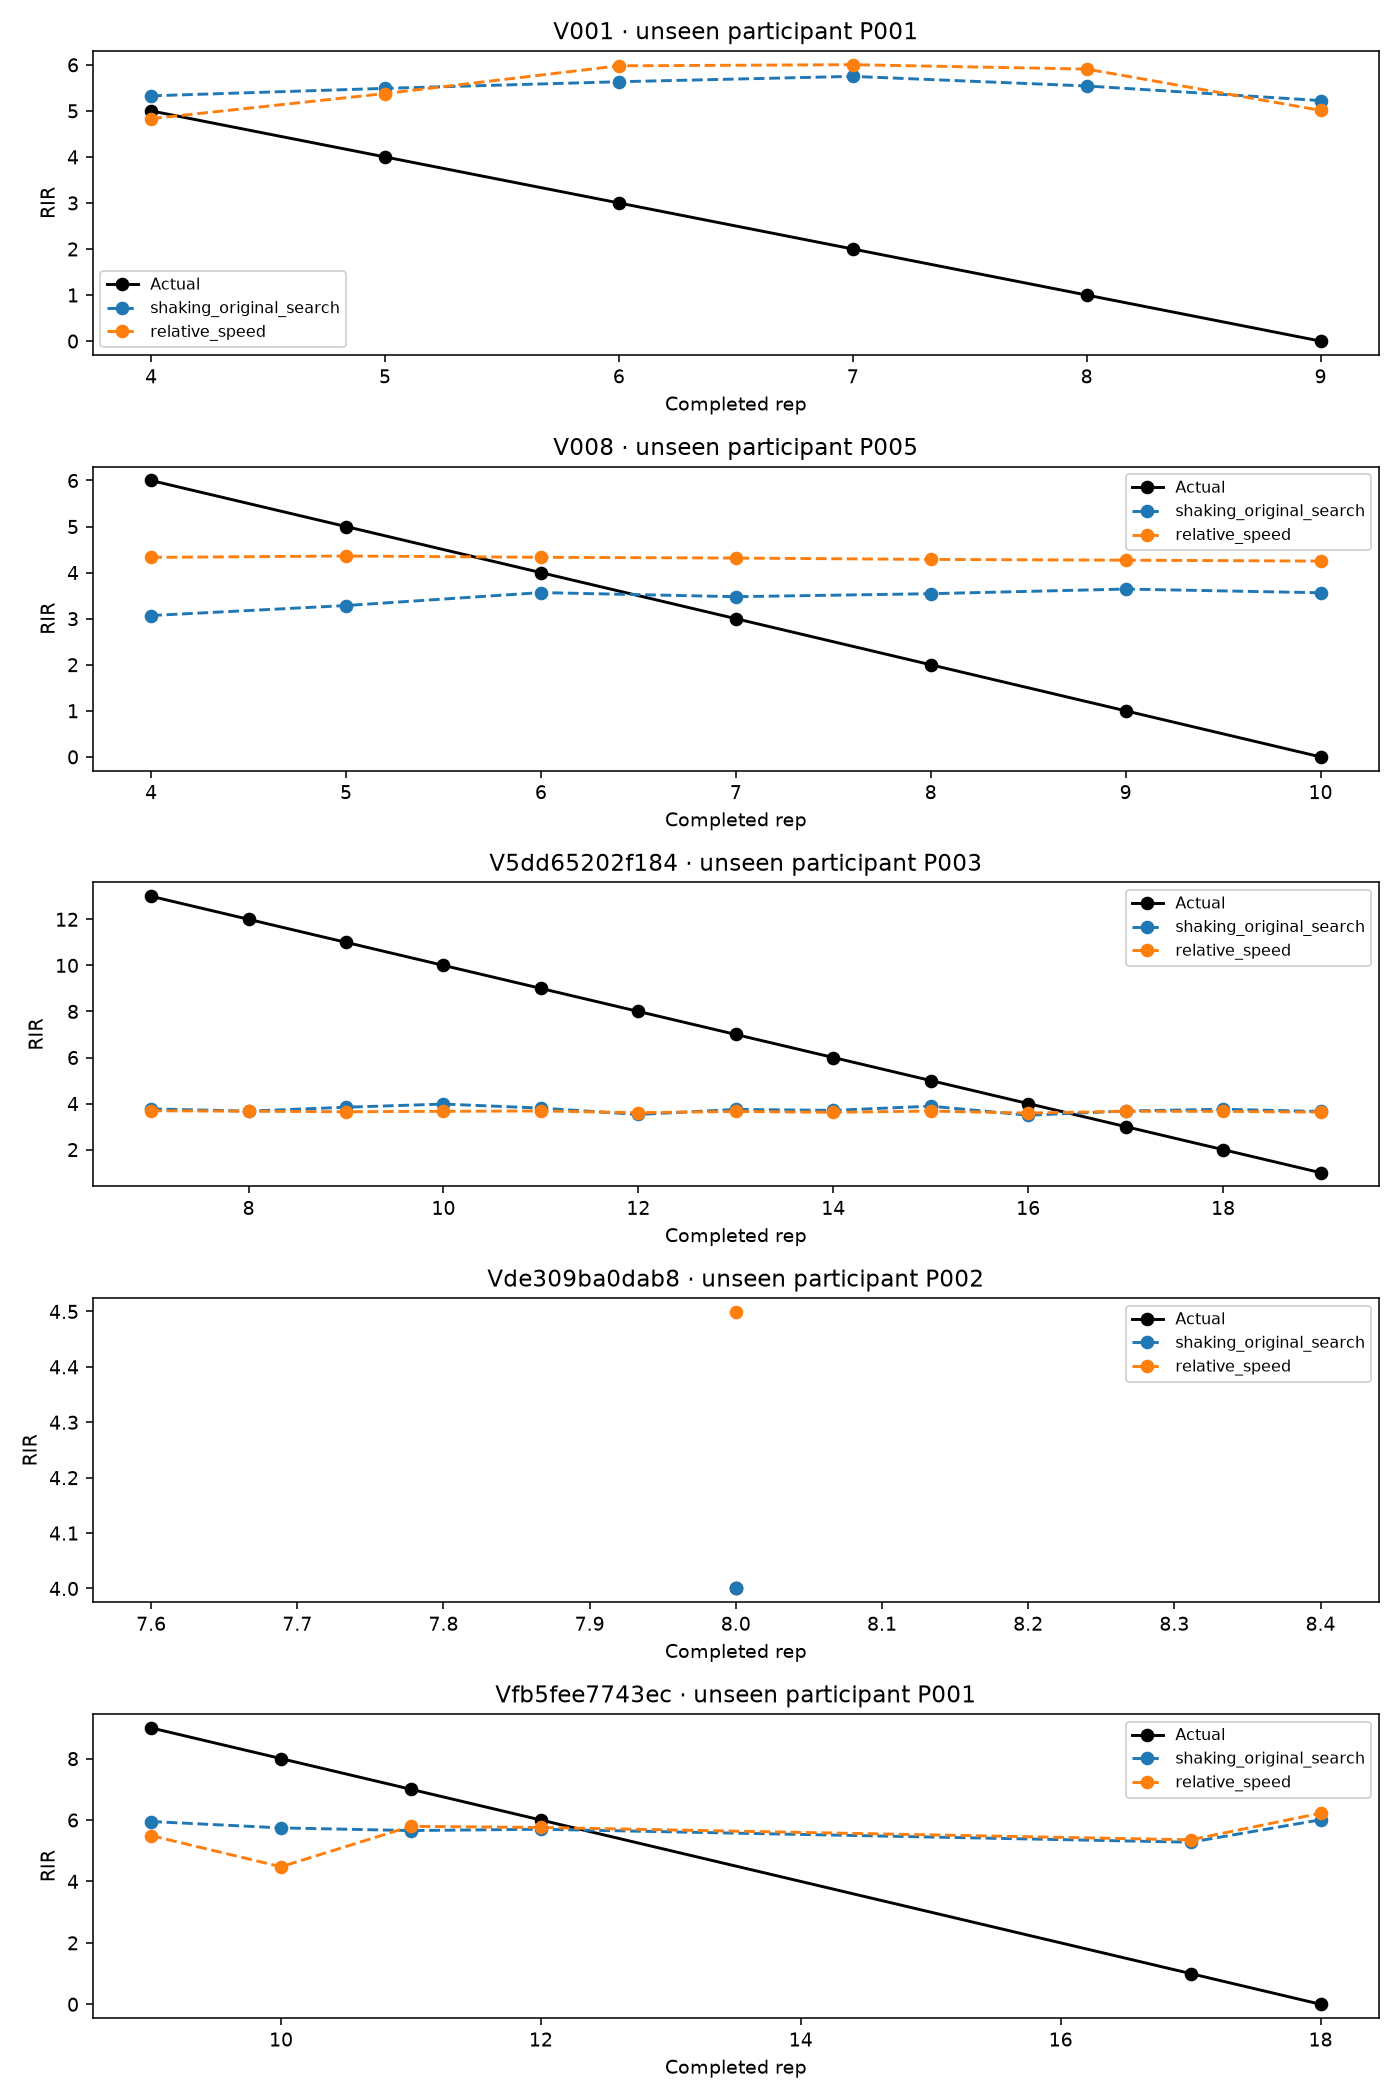

In [7]:
followup = pd.read_csv(ROOT / 'training/results/relative_speed_followup/comparison.csv')
display(followup[['model', 'mae', 'near_failure_mae', 'final_rep_mae', 'examples', 'people']].round(3))
from IPython.display import Image
display(Image(filename=str(ROOT / 'training/results/relative_speed_followup/recent_history_set_predictions.png')))
